# Exploração e Visualização dos Inicializadores de Pesos

Este notebook testa a chamada e visualiza o comportamento estatístico dos inicializadores implementados em `mlp.inicializadores`:
1. **Zeros** — inicialização nula (comumente usada para *biases*)
2. **GlorotNormal** — $W \sim \mathcal{N}\left(0, \frac{2}{\text{fan\_in} + \text{fan\_out}}\right)$
3. **GlorotUniforme** — $W \sim \mathcal{U}\left(-\sqrt{\frac{6}{\text{fan\_in} + \text{fan\_out}}}, +\sqrt{\frac{6}{\text{fan\_in} + \text{fan\_out}}}\right)$
4. **HeNormal** — $W \sim \mathcal{N}\left(0, \frac{2}{\text{fan\_in}}\right)$

In [1]:
import sys
from pathlib import Path

# Garante que a raiz do projeto esteja no sys.path ao rodar da pasta parciais/
raiz_projeto = Path.cwd().parent if Path.cwd().name == "parciais" else Path.cwd()
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mlp.inicializadores import (
    GlorotNormal,
    GlorotUniforme,
    HeNormal,
    Zeros,
)

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Chamada Direta e Resumo Estatístico

Vamos instanciar cada inicializador, gerar uma matriz de pesos de formato `(fan_in=256, fan_out=128)` e comparar as métricas empíricas com os valores teóricos esperados.

In [2]:
fan_in, fan_out = 256, 128
formato = (fan_in, fan_out)
seed = 42

inicializadores = {
    "Zeros": Zeros(),
    "GlorotNormal": GlorotNormal(),
    "GlorotUniforme": GlorotUniforme(),
    "HeNormal": HeNormal(),
}

amostras = {}
linhas_resumo = []

for nome, inic in inicializadores.items():
    rng = np.random.RandomState(seed)
    W = inic.inicializar(formato, rng)
    amostras[nome] = W

    if nome == "Zeros":
        std_teorico = 0.0
    elif nome in ("GlorotNormal", "GlorotUniforme"):
        std_teorico = np.sqrt(2.0 / (fan_in + fan_out))
    elif nome == "HeNormal":
        std_teorico = np.sqrt(2.0 / fan_in)

    linhas_resumo.append(
        {
            "Inicializador": nome,
            "Formato": str(W.shape),
            "Dtype": str(W.dtype),
            "Média Empírica": np.mean(W),
            "Std Empírico": np.std(W),
            "Std Teórico": std_teorico,
            "Mínimo": np.min(W),
            "Máximo": np.max(W),
        }
    )

df_resumo = pd.DataFrame(linhas_resumo)
df_resumo

,Inicializador,Formato,Dtype,Média Empírica,Std Empírico,Std Teórico,Mínimo,Máximo
0,Zeros,"(256, 128)",float32,0.000000,0.000000,0.000000,0.000000,0.000000
1,GlorotNormal,"(256, 128)",float64,-0.000084,0.072190,0.072169,-0.322277,0.323250
2,GlorotUniforme,"(256, 128)",float64,-0.000064,0.072057,0.072169,-0.124997,0.124981
3,HeNormal,"(256, 128)",float64,-0.000103,0.088415,0.088388,-0.394707,0.395899


## 2. Distribuição dos Pesos (Histogramas vs. Curva Teórica)

Abaixo comparamos a distribuição empírica dos pesos gerados com a densidade teórica esperada para cada inicializador.

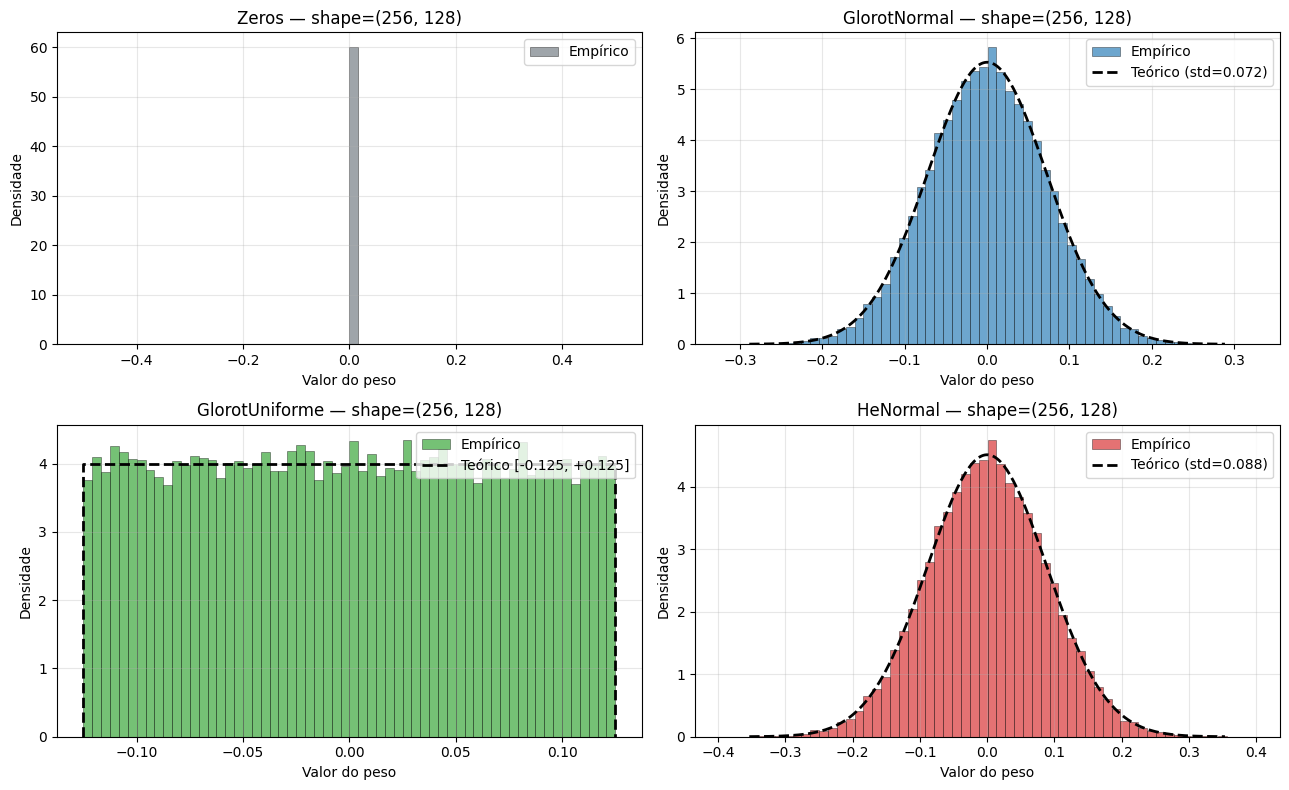

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes = axes.ravel()

cores = {
    "Zeros": "#6c757d",
    "GlorotNormal": "#1f77b4",
    "GlorotUniforme": "#2ca02c",
    "HeNormal": "#d62728",
}

for ax, (nome, W) in zip(axes, amostras.items()):
    valores = W.ravel()
    ax.hist(
        valores,
        bins=60,
        density=True,
        alpha=0.65,
        color=cores[nome],
        edgecolor="black",
        linewidth=0.4,
        label="Empírico",
    )

    # Sobrepõe curva teórica para os inicializadores estocásticos
    if nome in ("GlorotNormal", "HeNormal"):
        std = np.sqrt(2.0 / (fan_in + fan_out)) if nome == "GlorotNormal" else np.sqrt(2.0 / fan_in)
        x = np.linspace(-4 * std, 4 * std, 300)
        pdf = (1.0 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * (x / std) ** 2)
        ax.plot(x, pdf, "k--", lw=2, label=f"Teórico (std={std:.3f})")
    elif nome == "GlorotUniforme":
        limite = np.sqrt(6.0 / (fan_in + fan_out))
        altura = 1.0 / (2.0 * limite)
        ax.plot(
            [-limite, -limite, limite, limite],
            [0, altura, altura, 0],
            "k--",
            lw=2,
            label=f"Teórico [-{limite:.3f}, +{limite:.3f}]",
        )

    ax.set_title(f"{nome} — shape={W.shape}")
    ax.set_xlabel("Valor do peso")
    ax.set_ylabel("Densidade")
    ax.legend()

plt.tight_layout()
plt.show()

## 3. Mapa de Calor (Heatmap) de Matrizes Pequenas

Visualização direta de uma matriz `(16, 16)` gerada por cada inicializador sob a mesma `seed`.

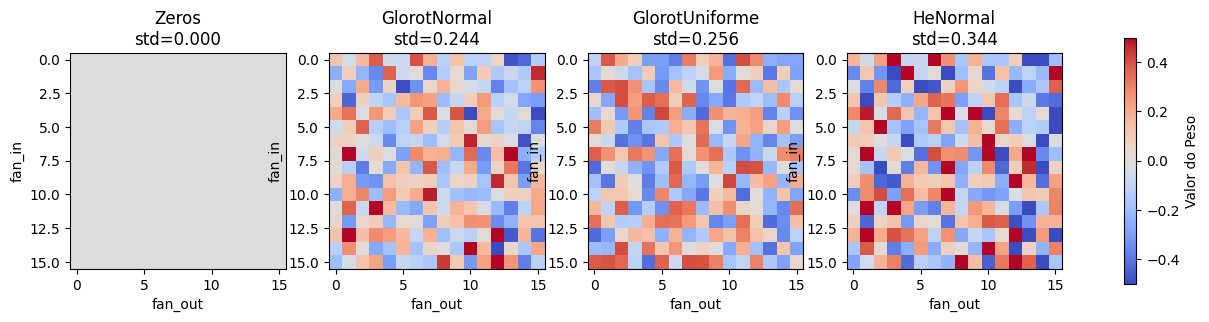

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
formato_pequeno = (16, 16)
vmax = 0.5

for ax, (nome, inic) in zip(axes, inicializadores.items()):
    W_peq = inic.inicializar(formato_pequeno, np.random.RandomState(42))
    im = ax.imshow(W_peq, cmap="coolwarm", vmin=-vmax, vmax=vmax)
    ax.set_title(f"{nome}\nstd={np.std(W_peq):.3f}")
    ax.set_xlabel("fan_out")
    ax.set_ylabel("fan_in")
    ax.grid(False)

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, label="Valor do Peso")
plt.show()

## 4. Escalonamento do Desvio Padrão com o Tamanho da Camada (`fan_in`)

Conforme `fan_in` cresce, os inicializadores de Glorot e He reduzem automaticamente a dispersão dos pesos para evitar explosão ou desvanecimento das ativações.

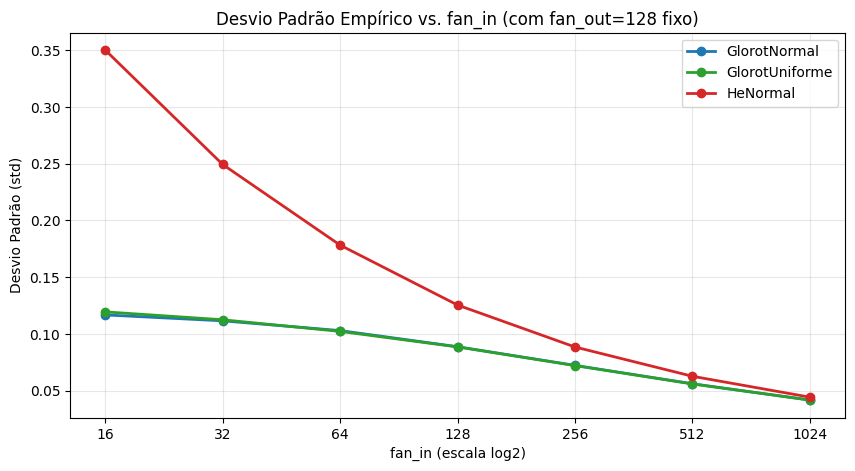

In [5]:
fan_ins = [16, 32, 64, 128, 256, 512, 1024]
fan_out_fixo = 128

stds = {nome: [] for nome in ("GlorotNormal", "GlorotUniforme", "HeNormal")}

for f_in in fan_ins:
    for nome in stds:
        W_temp = inicializadores[nome].inicializar((f_in, fan_out_fixo), np.random.RandomState(42))
        stds[nome].append(np.std(W_temp))

plt.figure(figsize=(10, 5))
for nome, valores_std in stds.items():
    plt.plot(fan_ins, valores_std, marker="o", lw=2, label=nome, color=cores[nome])

plt.xscale("log", base=2)
plt.xticks(fan_ins, labels=[str(f) for f in fan_ins])
plt.title(f"Desvio Padrão Empírico vs. fan_in (com fan_out={fan_out_fixo} fixo)")
plt.xlabel("fan_in (escala log2)")
plt.ylabel("Desvio Padrão (std)")
plt.legend()
plt.show()